---
# US Superstore Analytics
---

---
## Introduction
---

This file is used for extensive exploratory data analysis(eeda) on fact and dimension tables of the cleaned dataset(sales forecasting) from the data modeling file.

The analysis is done in 3 phases:-
- Phase 1 **Univariate Analysis:**

In this phase all the columns will be treated as indivisual variables and analyzed based on their composition i.e.. a numerical column will be analyzd based on 5-number summary, outliers, spread and other statistical methods while a cateogrical column will be analyzed based on value counts and proportions. variables which require further inspection would be visualized and this variables would be sent to next phase to find correlation and causasion.


- Phase 2 **Bivariate Analysis:**

In this phase the columns that looked different in the 1st phase would be pitted against each other in 4 ways

- Phase 3 **Multivariate Analysis:**

---
## Data & Libraries
---

In [ ]:
import helper as hp

In [ ]:
orders_fact = hp.orders_fact

products_dim = hp.products_dim
date_dim = hp.date_dim
customers_dim = hp.customers_dim
location_dim = hp.location_dim
ship_mode_dim = hp.ship_mode_dim

---
## Univariate Analysis
---

### Analysis

#### Orders Fact

In [ ]:
hp.info(orders_fact)

<class 'pandas.DataFrame'>
RangeIndex: 9799 entries, 0 to 9798
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   orders_key      9799 non-null   uint16  
 1   order_id        9799 non-null   category
 2   order_date_key  9799 non-null   uint16  
 3   ship_date_key   9799 non-null   uint16  
 4   ship_mode_key   9799 non-null   uint8   
 5   shipping_days   9799 non-null   uint8   
 6   product_key     9799 non-null   uint16  
 7   customer_key    9799 non-null   uint16  
 8   location_key    9799 non-null   uint16  
 9   sales           9799 non-null   float64 
dtypes: category(1), float64(1), uint16(6), uint8(2)
memory usage: 335.5 KB


In [ ]:
hp.num_col_chk(orders_fact, cols=['sales'])

Shape after filtering: (9799, 10)


,count,mean,std,min,25%,50%,75%,max,missing_%,IQR,Lower_Fence,Upper_Fence,CV,unique_count,most_frequent
sales,9799.0,230.76,626.68,0.44,17.25,54.48,210.57,22638.48,0.0,193.32,-272.73,500.55,271.572196,5757,12.96


#### Date Dim

##### Categorical Columns

In [ ]:
hp.info(date_dim, dtype='cat')

<class 'pandas.DataFrame'>
RangeIndex: 1431 entries, 0 to 1430
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   day_name       1431 non-null   category
 1   month_name     1431 non-null   category
 2   is_weekend     1431 non-null   bool    
 3   iso_year_week  1431 non-null   category
dtypes: bool(1), category(3)
memory usage: 10.5 KB


In [ ]:
hp.cat_col_chk(date_dim, cols=['day_name', 'month_name', 'is_weekend'], proportions=False)

Shape after filtering: (1431, 15)

 DAY_NAME


day_name
Sunday       209
Saturday     207
Tuesday      206
Monday       205
Wednesday    205
Thursday     201
Friday       198
Name: count, dtype: int64


 MONTH_NAME


month_name
December     124
May          124
March        123
October      123
August       121
July         121
November     120
September    120
April        117
January      117
June         117
February     104
Name: count, dtype: int64


 IS_WEEKEND


is_weekend
False    1015
True      416
Name: count, dtype: int64

##### Numerical Columns

In [ ]:
hp.info(date_dim, dtype='num')

<class 'pandas.DataFrame'>
RangeIndex: 1431 entries, 0 to 1430
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   date_key     1431 non-null   uint16
 1   day          1431 non-null   uint8 
 2   month        1431 non-null   uint8 
 3   quarter      1431 non-null   uint8 
 4   year         1431 non-null   uint16
 5   day_of_year  1431 non-null   uint16
 6   week         1431 non-null   uint8 
 7   iso_year     1431 non-null   UInt32
 8   iso_week     1431 non-null   UInt32
 9   iso_day      1431 non-null   UInt32
dtypes: UInt32(3), uint16(3), uint8(4)
memory usage: 35.1 KB


In [ ]:
hp.num_col_chk(date_dim)

Shape after filtering: (1431, 15)


,count,mean,std,min,25%,50%,75%,max,missing_%,IQR,Lower_Fence,Upper_Fence,CV,unique_count,most_frequent
date_key,1431.0,716.0,413.24,1.0,358.5,716.0,1073.5,1431.0,0.0,715.0,-714.0,2146.0,57.715084,1431,1.0
day,1431.0,15.7,8.82,1.0,8.0,16.0,23.0,31.0,0.0,15.0,-14.5,45.5,56.178344,31,3.0
month,1431.0,6.58,3.44,1.0,4.0,7.0,10.0,12.0,0.0,6.0,-5.0,19.0,52.279635,12,5.0
quarter,1431.0,2.53,1.12,1.0,2.0,3.0,4.0,4.0,0.0,2.0,-1.0,7.0,44.268775,4,4.0
year,1431.0,2016.52,1.13,2015.0,2016.0,2017.0,2018.0,2019.0,0.0,2.0,2013.0,2021.0,0.056037,5,2018.0
day_of_year,1431.0,184.85,105.26,1.0,94.5,185.0,276.0,366.0,0.0,181.5,-177.75,548.25,56.943468,366,3.0
week,1431.0,26.44,15.04,0.0,14.0,26.0,39.0,53.0,0.0,25.0,-23.5,76.5,56.88351,54,10.0
iso_year,1431.0,2016.52,1.13,2015.0,2016.0,2017.0,2018.0,2019.0,0.0,2.0,2013.0,2021.0,0.056037,5,2018.0
iso_week,1431.0,26.91,15.03,1.0,14.0,27.0,40.0,53.0,0.0,26.0,-25.0,79.0,55.852843,53,1.0
iso_day,1431.0,4.0,2.01,1.0,2.0,4.0,6.0,7.0,0.0,4.0,-4.0,12.0,50.25,7,7.0


#### Customers Dim

##### Categorical Columns

In [ ]:
hp.info(customers_dim, dtype='cat')

<class 'pandas.DataFrame'>
RangeIndex: 793 entries, 0 to 792
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   customer_id        793 non-null    category
 1   customer_name      793 non-null    category
 2   segment            793 non-null    category
 3   order_count_cat    793 non-null    category
 4   sales_cat          793 non-null    category
 5   avg_order_val_cat  793 non-null    category
 6   customer_value     793 non-null    category
dtypes: category(7)
memory usage: 36.3 KB


In [ ]:
hp.cat_col_chk(customers_dim, cols=['segment', 'order_count_cat', 'sales_cat', 'avg_order_value_cat', 'customer_value'], proportions=False)

Shape after filtering: (793, 11)

 SEGMENT


segment
Consumer       409
Corporate      236
Home Office    148
Name: count, dtype: int64


 ORDER_COUNT_CAT


order_count_cat
moderate    406
low         344
high         43
Name: count, dtype: int64


 SALES_CAT


sales_cat
moderate    596
low         178
high         19
Name: count, dtype: int64


 CUSTOMER_VALUE


customer_value
low         570
very_low    144
moderate     63
high         16
Name: count, dtype: int64

##### Numerical Columns

In [ ]:
hp.info(customers_dim, dtype='num')

<class 'pandas.DataFrame'>
RangeIndex: 793 entries, 0 to 792
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   customer_key          793 non-null    uint16 
 1   customer_order_count  793 non-null    uint8  
 2   customer_sales        793 non-null    float64
 3   avg_order_value       793 non-null    float64
dtypes: float64(2), uint16(1), uint8(1)
memory usage: 14.8 KB


In [ ]:
hp.num_col_chk(customers_dim)

Shape after filtering: (793, 11)


,count,mean,std,min,25%,50%,75%,max,missing_%,IQR,Lower_Fence,Upper_Fence,CV,unique_count,most_frequent
customer_key,793.0,397.00,229.06,1.00,199.00,397.00,595.00,793.00,0.0,396.00,-395.00,1189.00,57.697733,793,1.00
customer_order_count,793.0,6.21,2.53,1.00,4.00,6.00,8.00,17.00,0.0,4.00,-2.00,14.00,40.740741,14,5.00
customer_sales,793.0,2851.52,2620.40,4.83,1081.47,2215.00,3670.26,25043.05,0.0,2588.79,-2801.72,7553.44,91.894849,793,4.83
avg_order_value,793.0,227.40,190.42,2.42,115.91,184.05,282.61,1751.29,0.0,166.70,-134.14,532.66,83.737907,793,2.42


#### Products Dim

##### Categorical Columns

In [ ]:
hp.info(products_dim, dtype='cat')

<class 'pandas.DataFrame'>
RangeIndex: 1849 entries, 0 to 1848
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   product_id       1849 non-null   category
 1   product_name     1849 non-null   category
 2   category         1849 non-null   category
 3   sub_category     1849 non-null   category
 4   order_count_cat  1849 non-null   category
 5   sales_cat        1849 non-null   category
 6   product_value    1849 non-null   category
dtypes: category(7)
memory usage: 140.7 KB


In [ ]:
hp.cat_col_chk(products_dim, cols=['category', 'sub_category', 'order_count_cat', 'sales_cat', 'product_value'], proportions=False)

Shape after filtering: (1849, 10)

 CATEGORY


category
Office Supplies    1057
Technology          412
Furniture           380
Name: count, dtype: int64


 SUB_CATEGORY


sub_category
Paper          277
Binders        211
Phones         189
Furnishings    186
Art            157
Accessories    147
Storage        131
Appliances      97
Chairs          88
Labels          70
Machines        63
Tables          56
Bookcases       50
Envelopes       44
Supplies        36
Fasteners       34
Copiers         13
Name: count, dtype: int64


 ORDER_COUNT_CAT


order_count_cat
low         1782
moderate      64
high           3
Name: count, dtype: int64


 SALES_CAT


sales_cat
low         1823
moderate      25
high           1
Name: count, dtype: int64


 PRODUCT_VALUE


product_value
very_low    1760
low           81
moderate       8
Name: count, dtype: int64

##### Numerical Columns

In [ ]:
hp.info(products_dim, dtype='num')

<class 'pandas.DataFrame'>
RangeIndex: 1849 entries, 0 to 1848
Data columns (total 3 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_key          1849 non-null   uint16 
 1   product_order_count  1849 non-null   uint8  
 2   product_sales        1849 non-null   float64
dtypes: float64(1), uint16(1), uint8(1)
memory usage: 20.0 KB


In [ ]:
hp.num_col_chk(products_dim)

Shape after filtering: (1849, 10)


,count,mean,std,min,25%,50%,75%,max,missing_%,IQR,Lower_Fence,Upper_Fence,CV,unique_count,most_frequent
product_key,1849.0,925.00,533.90,1.00,463.00,925.00,1387.00,1849.00,0.0,924.00,-923.00,2773.0,57.718919,1849,1.0
product_order_count,1849.0,5.30,3.09,1.00,3.00,5.00,7.00,47.00,0.0,4.00,-3.00,13.0,58.301887,22,5.0
product_sales,1849.0,1222.96,2774.00,1.62,96.65,299.97,1184.03,61599.82,0.0,1087.38,-1534.42,2815.1,226.826716,1824,95.9


#### Location Dim

##### Categorical Columns

In [ ]:
hp.info(location_dim, dtype='cat')

<class 'pandas.DataFrame'>
RangeIndex: 628 entries, 0 to 627
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   country           628 non-null    category
 1   region            628 non-null    category
 2   state             628 non-null    category
 3   city              628 non-null    category
 4   total_orders_cat  628 non-null    category
 5   total_sales_cat   628 non-null    category
dtypes: category(6)
memory usage: 14.3 KB


In [ ]:
hp.cat_col_chk(location_dim)

Shape after filtering: (628, 10)

 COUNTRY


country
United States    1.0
Name: count, dtype: float64


 REGION


region
Central    0.31
West       0.29
South      0.21
East       0.19
Name: count, dtype: float64


 STATE


...

city
Los Angeles      0.01
Columbia         0.01
Houston          0.01
New York City    0.01
Philadelphia     0.01
                 ... 
Woonsocket       0.00
Yonkers          0.00
York             0.00
Yucaipa          0.00
Yuma             0.00
Name: count, Length: 529, dtype: float64


 TOTAL_ORDERS_CAT


total_orders_cat
low         0.96
moderate    0.04
high        0.00
Name: count, dtype: float64


 TOTAL_SALES_CAT


total_sales_cat
low         0.92
moderate    0.08
high        0.00
Name: count, dtype: float64

##### Numerical Columns

In [ ]:
hp.info(location_dim, dtype='num')

<class 'pandas.DataFrame'>
RangeIndex: 628 entries, 0 to 627
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   location_key  628 non-null    uint16 
 1   postal_code   628 non-null    uint32 
 2   total_orders  628 non-null    uint8  
 3   total_sales   628 non-null    float64
dtypes: float64(1), uint16(1), uint32(1), uint8(1)
memory usage: 9.3 KB


In [ ]:
hp.num_col_chk(location_dim)

Shape after filtering: (628, 10)


,count,mean,std,min,25%,50%,75%,max,missing_%,IQR,Lower_Fence,Upper_Fence,CV,unique_count,most_frequent
location_key,628.0,314.50,181.43,1.00,157.75,314.50,471.25,628.00,0.0,313.50,-312.50,941.50,57.688394,628,1.00
postal_code,628.0,56146.49,29183.49,1040.00,33018.75,57551.00,83226.00,99301.00,0.0,50207.25,-42292.12,158536.88,51.977408,627,92024.00
total_orders,628.0,7.84,15.13,1.00,2.00,3.00,6.25,120.00,0.0,4.25,-4.38,12.62,192.984694,55,1.00
total_sales,628.0,3600.73,7941.82,1.39,264.65,1042.32,3265.86,78534.04,0.0,3001.21,-4237.17,7767.68,220.561386,625,22.29


#### Ship Mode Dim

In [ ]:
hp.info(ship_mode_dim)

<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   ship_mode_key  4 non-null      uint8   
 1   Ship Mode      4 non-null      category
dtypes: category(1), uint8(1)
memory usage: 389.0 bytes


---
## Bivariate Analysis
---

### Correlation Analysis

#### Structure for Correlation Analysis

In [ ]:
hp.dataframe()

Customer Dimension Data: ['customer_key', 'customer_id', 'customer_name', 'segment', 'customer_order_count', 'order_count_cat', 'customer_sales', 'sales_cat', 'avg_order_value', 'avg_order_val_cat', 'customer_value']
Orders Fact Data: ['orders_key', 'order_id', 'order_date_key', 'ship_date_key', 'ship_mode_key', 'shipping_days', 'product_key', 'customer_key', 'location_key', 'sales']
Product Dimension Data: ['product_key', 'product_id', 'product_name', 'category', 'sub_category', 'product_order_count', 'product_sales', 'order_count_cat', 'sales_cat', 'product_value']
Date Dimension Data: ['date_key', 'full_date', 'day', 'day_name', 'month', 'month_name', 'quarter', 'year', 'day_of_year', 'week', 'iso_year', 'iso_week', 'iso_day', 'is_weekend', 'iso_year_week']
Location Dimension Data: ['location_key', 'country', 'region', 'state', 'city', 'postal_code', 'total_orders', 'total_orders_cat', 'total_sales', 'total_sales_cat']
Ship Mode Dimension Data: ['ship_mode_key', 'Ship Mode']


In [ ]:
mtj = (
    orders_fact
    .merge(
        customers_dim[
            ['customer_key', 'customer_order_count',
             'customer_sales', 'avg_order_value']
        ],
        on='customer_key',
        how='left',
        validate='many_to_one'
    )
    .merge(
        products_dim[
            ['product_key', 'product_order_count', 'product_sales']
        ],
        on='product_key',
        how='left',
        validate='many_to_one'
    )
    .merge(
        location_dim[
            ['location_key', 'total_orders', 'total_sales']
        ],
        on='location_key',
        how='left',
        validate='many_to_one'
    )
)

In [ ]:
mtj.shape

(9799, 17)

In [ ]:
mtj.info()

<class 'pandas.DataFrame'>
RangeIndex: 9799 entries, 0 to 9798
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   orders_key            9799 non-null   uint16  
 1   order_id              9799 non-null   category
 2   order_date_key        9799 non-null   uint16  
 3   ship_date_key         9799 non-null   uint16  
 4   ship_mode_key         9799 non-null   uint8   
 5   shipping_days         9799 non-null   uint8   
 6   product_key           9799 non-null   uint16  
 7   customer_key          9799 non-null   uint16  
 8   location_key          9799 non-null   uint16  
 9   sales                 9799 non-null   float64 
 10  customer_order_count  9799 non-null   uint8   
 11  customer_sales        9799 non-null   float64 
 12  avg_order_value       9799 non-null   float64 
 13  product_order_count   9799 non-null   uint8   
 14  product_sales         9799 non-null   float64 
 15  total_orders   

In [ ]:
mtj.columns

Index(['orders_key', 'order_id', 'order_date_key', 'ship_date_key',
       'ship_mode_key', 'shipping_days', 'product_key', 'customer_key',
       'location_key', 'sales', 'customer_order_count', 'customer_sales',
       'avg_order_value', 'product_order_count', 'product_sales',
       'total_orders', 'total_sales'],
      dtype='str')

In [ ]:
mtj = mtj[['shipping_days', 'sales', 'customer_order_count', 'product_order_count', 'total_orders']]

#### Analysis

Shape after filtering: (9799, 5)


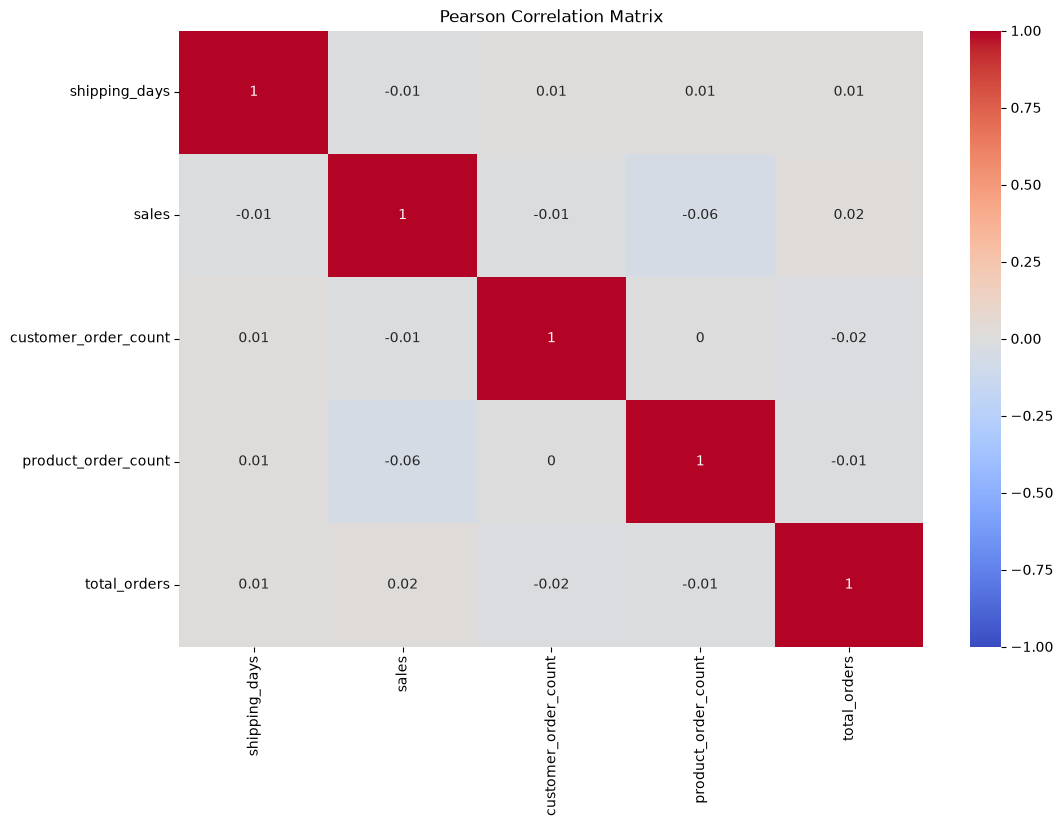

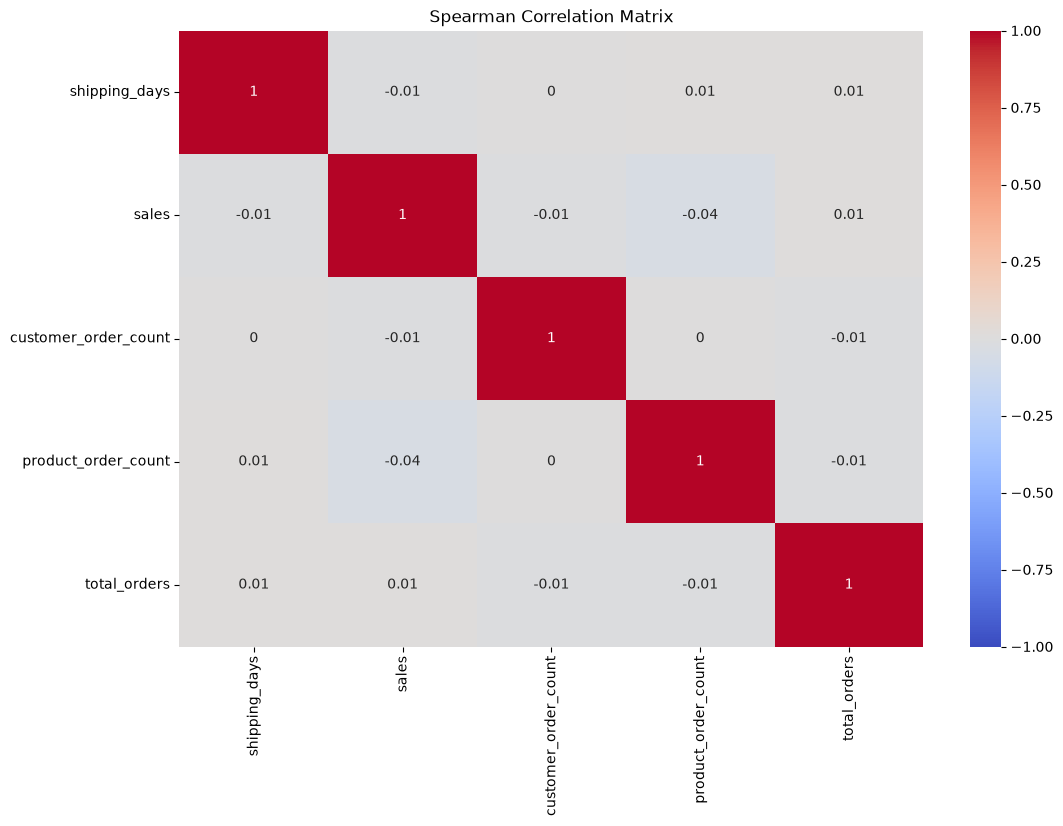

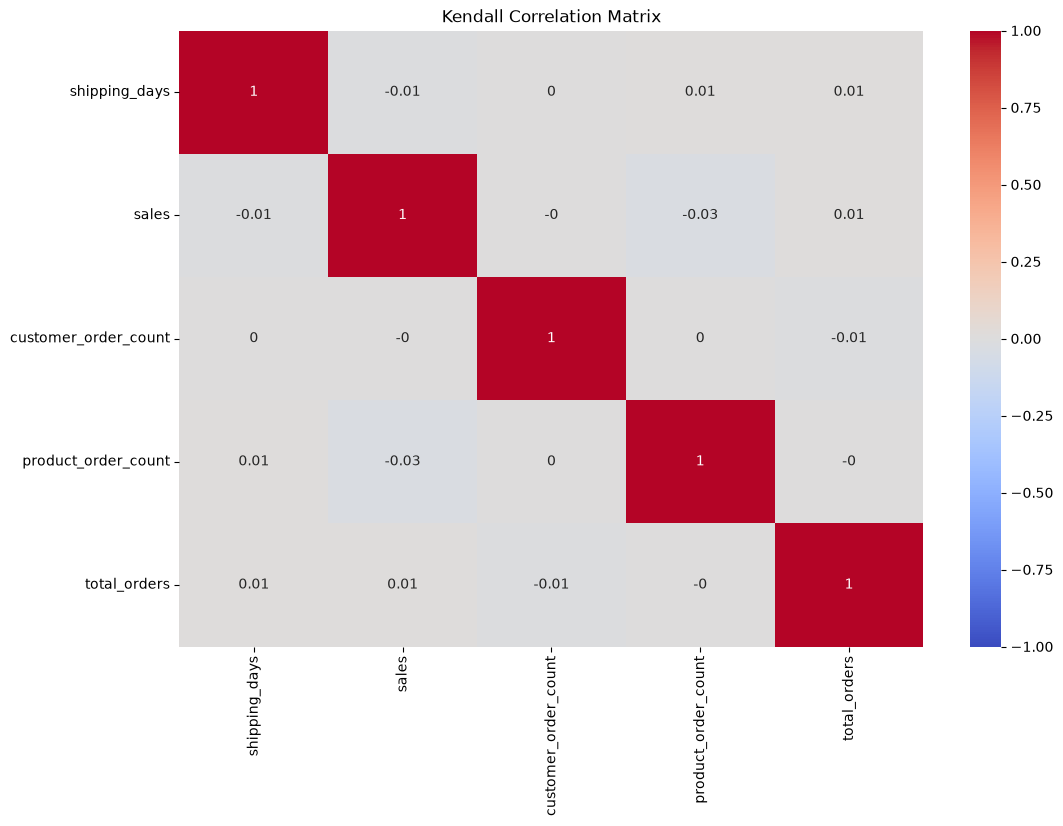

In [ ]:
hp.corr_matrix(mtj)

### Association Analysis

#### Structure for Association Analysis

In [ ]:
hp.dataframe()

Customer Dimension Data: ['customer_key', 'customer_id', 'customer_name', 'segment', 'customer_order_count', 'order_count_cat', 'customer_sales', 'sales_cat', 'avg_order_value', 'avg_order_val_cat', 'customer_value']
Orders Fact Data: ['orders_key', 'order_id', 'order_date_key', 'ship_date_key', 'ship_mode_key', 'shipping_days', 'product_key', 'customer_key', 'location_key', 'sales']
Product Dimension Data: ['product_key', 'product_id', 'product_name', 'category', 'sub_category', 'product_order_count', 'product_sales', 'order_count_cat', 'sales_cat', 'product_value']
Date Dimension Data: ['date_key', 'full_date', 'day', 'day_name', 'month', 'month_name', 'quarter', 'year', 'day_of_year', 'week', 'iso_year', 'iso_week', 'iso_day', 'is_weekend', 'iso_year_week']
Location Dimension Data: ['location_key', 'country', 'region', 'state', 'city', 'postal_code', 'total_orders', 'total_orders_cat', 'total_sales', 'total_sales_cat']
Ship Mode Dimension Data: ['ship_mode_key', 'Ship Mode']


In [ ]:
mtj = (
    orders_fact
    .merge(
        customers_dim[
            ['customer_key', 'customer_order_count',
             'customer_sales', 'avg_order_value']
        ],
        on='customer_key',
        how='left',
        validate='many_to_one'
    )
    .merge(
        products_dim[
            ['product_key', 'product_order_count', 'product_sales']
        ],
        on='product_key',
        how='left',
        validate='many_to_one'
    )
    .merge(
        location_dim[
            ['location_key', 'total_orders', 'total_sales']
        ],
        on='location_key',
        how='left',
        validate='many_to_one'
    )
)

#### Analysis

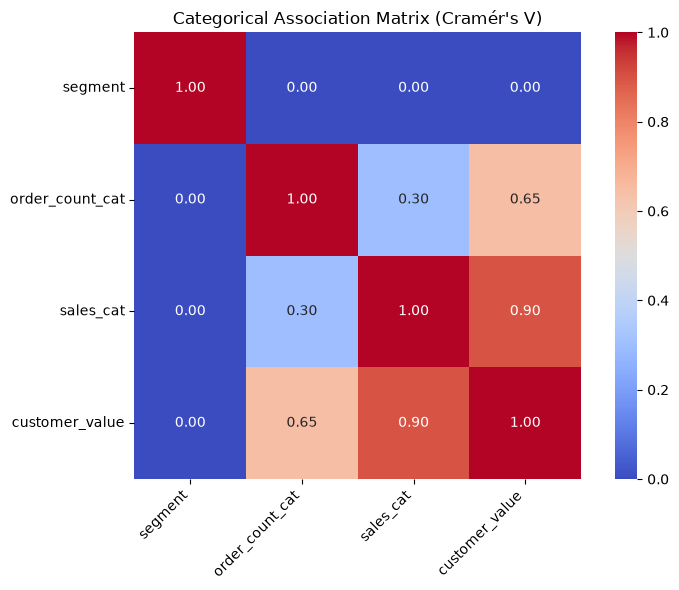

,segment,order_count_cat,sales_cat,customer_value
segment,1.0,0.000000,0.000000,0.000000
order_count_cat,0.0,1.000000,0.298341,0.645390
sales_cat,0.0,0.298341,1.000000,0.896675
customer_value,0.0,0.645390,0.896675,1.000000


In [ ]:
hp.association_matrix(customers_dim, cols=['segment', 'order_count_cat', 'sales_cat', 'avg_order_value_cat', 'customer_value'])

### Group-wise descriptive analysis

### Trend Analysis

---
## Multivariate Analysis
---